# 🎤 INSTRUCTOR — Group Activity (Class 05)
Student copy: `05_STUDENT_group_activity.ipynb`. This copy adds, per group: **a worked solution (pre-rendered, so you can read the numbers without running it) and questions to ask after the presentation.**

**Flow (≈ 45 min):** 25 min work → 5 × (5 min talk + 1–2 min questions) → 2 min wrap-up.
**While they work:** visit each group and ask "what is the population value you are comparing against?" Many groups forget to check against the truth.
**Pitfall to watch:** groups pasting AI output without running it. Ask them to change one number and re-run.

In [2]:
#@title ▶️ Setup — run this cell first (double-click to see the code) { display-mode: "form" }
import base64, gzip, io, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)

# The survey data is stored inside this notebook, so nothing needs to be downloaded.
_DATA = {
    "clean": "H4sIAFKEz2oC/41927JkN47duyP8D/6A9AkC4PXVM47w+3xARVldI5fdkjqqpLD7772JKzPPJnMeWq2o0mbyAuKysAD+/POvv337/c8v3//2+MePP3798fW3xz+/ff3x+Prrt8ePbz+/X3/5y7fHz+u/+ueX//XHXz9+fvm/3779n8fPv3/79g/5g8cvX//93799//3bl1/++sfPL3/7+s/Hzz9++f71719++/a371/1q/nH//j6488vf37/7duX//3H/1xH++WP3377689vX377/vv1fz+vn7t++ueXn7/88ePb49v/+/qb/Ot//k//8m//NaUEj//++6/XD3778f33Xx/4gPGRHv/jj59/fvv7g9JHeZQPnH/8AQ9M118hXP8oH+ORywfYIPj4169/fv0v//bLd17h8yhQPvJj/g8e9fpTaPMf89/aNXLBj26j0OO//fXzmsrPn9d/+jJCu76lR3rQ9U/o11/N/+VrgDpigPy0FpIJ6xhYrzHaNYvrjz/6I/Eq5jDXHMZHtiFKzEG//xfZzx8PyNdvz2+AR8C5jiLruHajx27Up2nkByJP47drY+Y2zJ+cC2lzXWlObK7kWiB+FBuiPW+ojyFLmUcyf3QupfFSgHg91wpzbEd//OsldL/+Pj+Hp5XQ9XG5znZ+A3O89BiFR+hzBJ/GeBGOdUNpbke9Pm+8Fp5F0lOt7aPpGJCel/JyKjB/8fqCrkGyDMBrmZtbi68F4NOGPK+ofNRrE+s1R5r/nENAmXtWr8Fz9SUBnmSkXXvCUnmNUnhJg2XkGjt/JBuCbF9JZsFHe4khi+gluX5L5sf8L8kFDHII2POpXmuvchy8FUk34RKKR80uXFA+/bh9DddE4SFfmHjPi9pL/Hr9dMVWoWgsAMDSyLLZC8+CHq3F8tvTDj7fVBShSFNWrkXw5nZdSekhFP1uDJ8KTtmco0ypGLyYPvgsr1EW0RqLgOM6gHxfroGnIIhQNZXNFtPA9DqN7jcVeIgpmHnu6lzSnMKjXFJmn8NhJ66hpkA0vqRJtvPSIHLHyqXGbBB8Eoj1SBtrrMbatz5sK+e+1rijSJ/ul8skEstzXfaRpzj/qHY/UczPQ3ySjHkB6jXtzOqXJVMEDOYww4Ypr1drWQxOrTflqvAF5f1MfKTtkUP/Yn21JE/3E1m6CovoNUtUyerzjzEGaffHKmPMa9Z1V1H2pKkGvo7Fz7YfbgroxJOvBRrwGNc8aowx9uI1Lxvf9C6Ds67KUy0XP1pKMQc3qfPjeddNvM0sy2bSPBlTmgTr9+tGgmjGyiMUF62pwy5dZdeDcGeQBwtEY0s4WEcW3cIWqpbo5uev6UNnOzoV3VywzDyb+biEweSS3sjlJV8ksuziTSKXdZVL+mzTeR6s167LdJkddQhwmA1s8XXdKey5f9NgoJwCHyCyisAPtK+bqSh8FSK9h9NCUKg4vrGhYqjfzD3MBftTrqDEVvVpd1wExmIu0uvvT+sAbC/Y3PL2z2nF3uUU83/5Htknq4sTMorKcA/DneGg3kCuQPPZTyWzSFDGk0aR/c88hCp5uZhl1a+ZnnYQni5B44UTX2PxPZC35bISw69BzhudNGV5KkSdAf86X3E2P2F1c9lOgaX3GoLYeXFl1F5mUG8vgt2mwqcud5HFuOmFvHSBCWJud35+nOa4DmNKPopvO8Wgz4k+KIQp9zvHdh2judUmMXa9qQt2nYgPM+5DjmsxJCIoBqtJlEDJvLjuQ5SD4Ra5bLylTSxms3ghdHOB437wBkwBK76rwLOZDm8F39aCt37pZx+AFqesymUzl67QrXytjpmMMq2Vyg8HDTg3JVzDkk+285LsKWqD1R2uyvJaELmolXLel6lo2YbLjatNb+2l8+zGlXofNczDuTQL68ypsOTai96cKwy/rLSd1hofxFZ2iimJU8UhGF/ZFlPoNzdOvLorOGGdPzePxya02xKhUxkvoVMcKPAmTqW7etl1am9TW/XObtv3dEni5d3zUfL6O2t9/nk7yQqf7nt/OgXkUKHyNLIoHipuQcN8VNweBSHfDtlKOYqS+SiArbGNQHvVcw2W+V6Jd5hsFnODLn/INrPmnZsOYoQyB00kqq/Yn/Xst6yWu4iLeC+RFZ+qG/Vur48j4qpHl5Iv1wycM5s+vlcS+kxJS24Ia7s3RSLU6KFCExPCfzu9zNxiH55dyv5yx8WYJXYmeGOauGWwurZ13LuEGv+bFZBLZSb+Ok77vh2jcZj38JH5I8QFIbmCJxOpBrdYzxosDN4N4EiF1yCxbFkjwIYbuRLbLucI7J/msO1zhy7DaofS6C6Y96mwWUS3rBkUq7lCSJOslm9vmu3H4OveWF0p7gRVY7ASGryVI1yTeUcSuwlFjor/UQUp8bOpe7sI1w82RhfMXaJi1gRiHq43nzyE+Z/zNR8q34IrtKm0fSv7J42nLvIUhuQ6ggxo6svyxx7wSrz2rHiAO9kMslQfoaf9CMSBOLDKloMkVOlYwMMOx1tuiGH1UJqv6dzMGpe8485Rm9ew8fUCs1tVnd0FGum0t3wcVsw5c8zH8lgM58p+LXo+41w4D1ExHj5XdtLmH15iYPanlwPGNPhABRCA/ATahafX6wEGTQzntodgW7yPMIaZjhpraVsz2FSIkscu0FVHtIh/+z74EWCja+yV1Kma3nQLILaPI/SIi3NGciOHadzYzJFuNnPeKgafWUVNd1/UZbIYJsX3n4Pw2MoZq2QNwnQZoI7n5f7bOga+cRCnoWGs8UGmFIa5duGrDjqDbvNcq5ogVNs89JJc7rsPk+80BQAHEBZP8tA0WDYZkzChGOXoMA9FmmQOC7ABq6YcdRtUZl7EUGgk7v30FQIZGe00C1U5At0F8JYF7vJ96HvgDYbCoIv98ughrtkY54QFPVTr8WEMzXhcVlSNMaR0a3jWMx2+nzKPIUBPnkc6bJjPQfp63btHyXpXizlIgdBDwnuXG5BtKDzEy2c/k9QQN4yV0AmKhQdjj4JTUP4UQ0F6DxXJKhSsaeaWzFWEdwOpnMBtgZWzyfiSeMHFDEOqnxSfT4Q9GA74DTrMZNqrm9KA9NmQqxnqLIrgQCxUc5fdDEHqJ/yzasYlMy6dFuwu/ExI41a4A2Av6o0BZwaTIZh8f4fdEYC0rKO/BnKFs3HzorPygq4+UXftCQD32B17qhbI5QikslgQss/xHoKsrmYsDGO/Zuqq4mlNADr6qE1zI6stlYtRFggO4BiWd5aHwmh0j1QeizjGPpZX/+jVKwC2p8RL4GvO2mducIlR6hYMzBwFudrk89BM76U4KTa0nbYEJLzvPI8SKcF50Jdj4INsonPJvhVV/iMSJjTP1Pdz7Jy0xpIt2QFcMMXrmBzYB0wbtW2qfwaV4yFgvt8wzoA4xHFtzTlA1yCosKbANQjCJbgGxHMspUA/saulw5DmFLP77oD0KbC0AwHV/+CC4RbR8UnAfU4SNSEqAQAuIGtblT+WXap5aCYuhSllHT6zlcv39QUicIg9eTaxL3ALTr/Xl98+TX/NCzdhK/hNr7aDiwHEvvEHJAABNhNT1SnACpZtD1WD4+6KhtIdCpZ7QtOC0exDUHq5nxa+scs/9YMAolm9zO5xA9Cn/LhPXu5E6EnHuy5fxiSA8JDox8YZM1x0FG/ytL/++3QPmA2HLl29SQ6zTpzf7iTlU/wMTT1tjZ8ZpyFHuyBWUV6vk6XmiUOvFx07zzWyuUD17GVz8nFuJQX6KShPXhAFoPbmMoIiI3yWEsNN5dJCDPom4mjqyMZt8DzeFS3457ekDV8GTU3CEQuHjeIh81gzwesuMuSjnoR5rxcvHeRS13m7fATYqpXBBBZiTa3ouuOoyU8k44GbhKBhaIDRFlUuDnKmsytkfn4x19bcqeoBD+S8S6NaTI8e0wOEwfLvy0sOUE7Tc8igxq4LEpwndmqKKdcXR3DFTuMcUW6FIlw47Z3dzNzeIArkGJdpCMaBm2yk3a373I/hn0mZVR60ZYUeS4sRdtG4uHOFtWFIVDb6SvNYHEra8MwEYCH1a8WZSRN7dVtnh1FgC0oAqzm5XksubnqZzeFkKLgdoCzGtkaGZU5n8V8K3bu0mJSghs+hAQmpwPcg7/PRTe0U+6NlSU5EAH7FbndGxvw/cYiL0/Tm9+EQv2R2XuJVgbDbCnNm9sFgLsT3r+0xsswjdM7nK9yY7V63mEXfWAsRJFJ756rJUnnXJtq1KrfMjDX7F5paLrYCKmNiPCZLa57nRbOg5rnIV9IVs7yiPNPUdR/cgLIzQN1oAkMb40rWO3qG2HxyP7gqPaRbxO70Cqi0D1NBchpJM0wujMyZCJtZ88ZUCeWzPIT4yX/h8dJ1Dr6EM3A+NFSF4NmQWtwanletGwxfssH1MXgIRxpJTyJIilDbyf8pDP42pfZ5VMMkypCp2k9oIyMuzE+csZoQP7sqhxIBc91A6ZGOKJrC7SvjgfmnNkZL9+BB091M7sfCkmsz/dLgzW5WHUJ3UmKCmSyLE5nJnbsZwLQwCgQpA1i9eU8MQaMdtscApWk3NO+nyaUw7dryPYAzZz/3yeh4PWL+Pg2FnWIrO84TMwJZBizjanyZHtBPq7e2Xjhn5SEheTIHdl7PBbdpW8DcqRlDY3MwxRp+X+tbx5MdMwZrJJZRAebAFuPkx9ZfKwoNh6NT1H1pnqWFnk50yKaCGjqt2+574hv6u8T30ORidhmuVTdy8Xn6G5LvEO/mgUpY0Wxcm56P7Uank2oqXV0kfAaqGf8KW983jHSBiIWPIeQ1xsuNy3jF9r6UcoQrEqv6zoJVFYPqhh+VWEw9edKFg7RLOUguojlKkGc23uSrtzvHARccEJ8JDSOclt73jhvTsIyD1cJg0xqc9bFNv5ORQheTP39+Oo62iyOd9Dsyqkornd78tisMsDUMOGU5u6ajTKSqBRJBfILxJp654tUekciICgnbhXGnG83cGiG0RZRfxd+w2zXyHuWAxsCXZNwxMsxTSrPzAWGUA9Yy99GI/MXiiCKArs+hHlP2NDWlZk1qYPSwGtrR7v0eYBheU/7EV4DcQkRUOU40jKxBxDwDJS8UTZYv7uMY2xggs6+Aa+LHaM7NU6OYzsG1sIykSiQ9ERPbgtrgp9qdF8CiKz02DH5HYyc69oUviZtnXJgFUItmXKsIy7SiHSreVu7I1SalyBrJNSdFXiKdhy91O68Rql7wmbQGrvJg6EpphSPWsc16N03eB26iDEkudvFZ1BeS0ZKzEfxIzJVg0kmNV1QTYCRt8qcBug9ACuIN41G4AcbU7yHEqWGGKrkSyLpBDdU9CEzjkMgjzwXOaFvyqkXvR1AQENKGtj2/lwoTwzALWoxO8Tm8MIbVTHTl8zC9FIJ1j/NekH2M7+Ea0DS3DJKNCuJhGQLtqVoWWWUpICjmiXUh9Pgi9nYbm/pC5DccDXaZWTEbodwj2jOuMjUL4QmyO+GAKN7U6ZgjKWw1eATdz2t0Uuxj20oS8ZYzs5XWzBlrhbiTLxU69BoRpQfvYVlxkrEQvBDGtvigMZlpClJVpSI6Zcx7bToF05YNpfudtExLmDzGXSwOpOLn+hyPZIBjAQViwcwtSf2DnQLijUctNyErS5mJYGtKO/gviLS1EiihhN0jp3wvv523cydJytDC+CavPnFvA7G8YW5OrVTc5amedgyV+FqN8ykc7SzL4vUI7xFVEmqPY2i7GgIBKtKSHALNp5clpkPsW7pH5/ROUYRAVILtaIBmiEcmEPSFNEIBYKJYOZsGpX0dAIqCo5W4QqafQ6gJjt4PGJW5CP2dJHWZGMEgTz8i4cELY7YfRWURkOGzQVFAolNlJ6mWjEpEcM5F802l/CZhkpQuIXAe70cbhnnU2NeyjZnNp1XfoVuElePjA9dCGU1t8Wmz0as6xG62DXMFxBdNvpNd6zED1Ubq26LlzOxoYEx1Sddw1UlyQ0H3orlikaSFpew8oNZIiXNPfqI5HbItER2o4c8qErNszQY4VYIza6RrJlqUPhsBLk0orvIyfjL+z6U2yVPzYLyuHhKVbytrpXCb1BtekkUwwwNz/3L+JEVr1i1p+nbYzLVOyT8vbwqMDXkgvtMpimNXHhLmeiyR0ZrpseDCxeK86nEe5vaOFzaNpbiCypqRzFH2RAfm/ilcV2d4KOHkyXozFBVe3Guy5gkFTBzjSjmo+DDZa9hjiJKO8LJUGUtoInUYphqiuBULHOBQxmW7YtQLHApqEX0i+AZUYmBP0TWm03r1T/PkMhY6Ugabln+TEz6KQsQ1NF15pzGL8mckjp/nMihSOD5MeUN2E9JD01RYsoCpS17Th6kn7jsm6/Pg3NRhkfAyRttqHal9kvxk8u+nUmwYu9rvbjwkzUnKtyKgxVJpI8Rjj1hmRWTAfx2NiRTMWqzp3kuH+qR0U8BqOPWVWY4K78rYu9pRIxOR2Z8SSrPiARxjNcWK06u2ehBi7bJX2nQFYEhGcvs9+AIwq5XsCGo+Nu8QmLJycYux3LwUo8UiyoHm3NnblLSBiFITEg4sJQhY64lB070gzxM5oFFDdrId1hMXyLiX4taId1WMNh6Kq/a7+DFOVYaBRTbUw2ISqOnwOo6VJY19I4vCnmtPL41hB9vSAZwZzB5vS26rSyTRl14i2PY0DCHFtqUGuWkUtXjfbVsUAVL/1Rb5VstcFg4ntpOvyW1ZzJikcJybBDN2UVven2vRmj5k10QomGDKd9mHsgvHunoIiTUdSxq41x3au9UjHZQUF8OHlcUpKSYv/TvwNscjUFnSSZh/QcW4QQGQtH5MB2Svy2ePO1tSgSs0w9Vr58KIrtlvmbz4eVk9rshVYk8bZy9rFXYQ5qRyakpbTKLD8YJ0ZjOgKvBihUNc+eiV0djxCKQKJUGYa/mxXLK8xhAvZTufSPTI6suYNq6+WPV4Lht7PqgvmjuR1Zoq60q5X8hBiQ1SNgg/12KDRxJUjQYawWWvGw9YIenkptBveaDAvb2pJKiqsMKc5xqBtsln74ceTshOyXIWzWqXRgwwDl4jfaBX/xazRUMzccsle0n3vFwS1MCSnPBkGa+ocsEB29ojgxxjP7v5aOF+D9wx34kx7GKuL0bRDy3JIhx0NMtGKM2OaQ8HBEMkxkkmcU6ZM6nW7ScKTHwWZc+18QIqIUwxps5VcdMukefucNQDvVjCKQmH+K969PkxmRjt0ASjaT21YWmKQNFSXIKjH2DxzkZQnDRQXxMsvg4sbIwdCMXKVatCFEiEZBWWjghTSmdsOyv5zFP0ZMfhiSdKb9pgodjCsaiq6Gni8DYlPFW5DG2bQN4ZRGuBaUa61cagow0x1EJyLrBU8D7PJL/p92Pt0p70N+tfG6Gc7gmzGy0UypZUVf66XzbatWyLmgAjJ+q5gHVLC3tIqZ3TcST9TqarJaQZ/hHt5uAb0s/5UR6khKgOKysr7nDRa/HOJ4++u6iVlUaclqZQBGnXuaa4PTFKPSQ0uNTL3em1ZdtNzYmka6tbtdaUOhBNkAjeFD9KR4hheWew5Jy2hrDDgX1zwcROQlqSlMagiECVzlU83n1JmFledqipVh9k3whGGkP0h0prNILJS16HbvNCZl7hoR5bNwFtQtDxr889YDivwIfLgY0Uu1ttWFkOtu/za0MZ1ZIbalG/WZdqAVpzQ5/cPlQiarYGMO4nVS8YJzz3MWhahrWIeLLERIgWwhufByxJZNVIXjbQYxA8dXiSelqLjqLDEsb3e8E0ZYVSoNxMKLp4oHasmI98WLlkgUtJbx9FHm2Icpe0tX4+IMU/GKwUZhL4WdQ3MYn08lvShUNr04p7z4Tt5D1LGevQNE+0+uBOYmEesZ8gbPSaLMNelYGZ53n6GONAoxtaLhCKT6sGgydEtGcFk5c9kFlVSdc0Z28SwT1uy9mIpkhQj5MEqaO1kyTcFgxYhTwEhaChRqi9xvxpN4JwEIygzhommud4vo8on3JLwxFwbhDZLbmUhSZuQkXlDK01wWxZSXjbmHnlqccY9R4ViyJztCxb1ZC1OxxFdMt340hDJTFFNmFaYPvuUCmRWZPgZ55WmSbPRWAceg/mD0F10dGnRgYzxBA5vWl9AM6UWisly9K+kDLcQxVVMyHyMeMeSi8vE4qz/Xup3nn2qWgsVci4trCF1d7dNm8TgNikyPhyhNpxJ3o3UD5JIsMcxfs/LL2o2tKEkHJ5Q9VKSq31bpKmVGyAepgEdHfG0GjN6D0MMTaivSk4HQsIpgzdovXQl1j4kR4VpJVfwMMaa8KwNjU5NmTc9n8Ql2FN15L124k0G5V0EG3m+UVXqxLdoGBpYksFDl6U/GJU4Ei+VLo/+AB4YveAt35ogVIwk9MTD3RbwxNJKQuKaaXX9InO+j7kbUgrrWbokaIloGmY5og/lXe84K4lm0VduRrIsO9DvbP6kJTuBk72RrDK/FCPpe1KdkEZ2mSq3XskRNKdyps4B9hUJqtuo5CFtt6LMvZkzsGaErVLK4/f0MBQB4uopje9tkmL27hFmenKIQX6JhAVtj3OUFs3JaeUQqlaLdmdSEB1CxiBOZIYDICW9HL3FguhszurtTO0dgwlaxEWDtBa0wOvoBPxUtBJWwDWdAFiHmVT/dG4U2VZqqrUAaO5DAsOXtJAr1qCDF2OPu45BenIV9GO8RozjLSkh1bzwysxdVn7MaLnBXEZuOTGhvG+OZ8RhrSeK3I5aJoXjjzTmku077F9aelNq8lqTVICXW7CnDbV3faa07yZaAgsSflppuO6tYPm7NyTUPDdFn1eNOYyMW/0LmWaH9pzW1pmC/IddCFqu5ozklyn+3TobWbCI2hv+rs0rdpzuIn0pga/lNox3uGeTk3bBRRvTaXEBt+GHYdd4t+u9AwYwXHNU7xNpFo/cNGEzoavhaRVGhbYDWm7VoLF+yomxVRz1TrUSN9QT2/rilHvabYSSCkooKWqhDocOi8gm0JxrjTgUPbSWhJLfdunurBMjqW2GTxgCcXZj0Xigy95fsi5eNQnLJPQ3z0f6v4tYQBPL0/UVTJ7OSQ+ktYKiVci5ESrTY68B720bXvOHrHZc0IIOUweQtXb2SZz/akmklSys5X95xiln1EmYLjcwlB5ISBraBp9FKjvO1eT4hKJm8iCN97OMpSdyEgbXmH3QjQtQwQr7h2Bagw4xQ7GiqjinmA4SWXhe9LAQ/NpTb6MtT1YXRHUcUuHa5p1SU99DxhaKPFpvg99s7pQ8PSkAD01LKCxS0IauBgPEpDAF56roXHqHNg1jRAtZ5vVdy83YbRDgU7Tk4qm37UYr6fGLA4QJTvST+Vi9LkQl3at2URHR7Mk7eNBFC2mVUPmlA4+vnAFkrdBFoslrRvQBoDbSCuZneuqzSg6CHf7FPdxVvVHFMzoF/Pvmxce5kR7/r215IxgkzAI6MVG2HYqQNCXLaKw27JUPcf+Hd+TsC6UigH1tRg6OPw51e0hcEKLw93k7HN7cKXFPrTDKaL2inJsFa2mpcQAfVsGILFSXvjJUM2fdvOU0zgncbO3R8Wl0wBTzFQVZnjXJxCVcrP0qzJWaBjaDEfKBhYtFsuSnm9WUCCJJRNNeK2CfEpMNX1QaKETZcmjkn2/xSdBG2gU90CHX40Ue/GuVSBDi5WPEXrUdnAdpMkmHBpeDe/82AL156bUnpHOcOj1Wz0f5e5bWnp7+zraGexGVfQea9VPNXMZ+pavTd7nPK159TZZwqagYJydeZCMZzLnrVtBaAlN9ZrJuUGFuveTHrGhRToNmlRscjnPbKK02D1x4sSzt6uK+GYuRVBnst7z1V/TwZjJvgkwgYMjpve1HrIusGXGfOe4GPIc79ZUp9A7DT5jeVuUEW/HaDFjg3g0xedQ9916GJzhp1uiUwxRFJmYkB8bs1V9FC5F26GmJjDAxrxtzGYKtKrGIePSyLMTc4IYixkn5t5UO0Pz4ZbSQd2RyJFlSqcS9KoMAa+OsIYtUTCTCd5QJqx5IqdXaHk6KxhW+diqTXP7qGsZUSZaFypKJnrTw12gs6cuulBSMHPshCnvOZVV60Vo7RmXJZ/tEynHiAPtNQGSliFkTHYutnRHOdPWyI+lkrqurVvKQqjP1Paxl8gpLCGkNrdaGwpl6vu2I3PqmalafK59bWGbncqYXwuBbrLRqIGokcIHakCdHeLPOX0KOXyIrt4/BSknW0PFCO1zhgPpKxJg8NwSngtYbUczbkKIru/M0NLLrxs4EfY107lhQ5JHSIZH09N5yQ7Q53wivmmb0sY4T7GwRC2T98vO+T+Qgiza40kpnc2ffcDYirrBq6aNZY2hPIecNY6LFw5yPqtQrVuxYsNuESjGRvZT8zlxnlvQhNusjjAPI48DEty89Cat7zPggp/msmMIk0dQ8/fxidkQtKx806xtjQThoa63cu7Kp3cjczmwM4q7FVVB9WGRpMM6udC7nh2G1i3YEBPHKbZhU5o2ODPQdBfSWrvaPRLNn17k+dQxA71Ag6IlThM3y+Rg17pNSDvgTTolWYTD0IhlhPaSoOCPuxqcl7QfSV2/f9uP/db49U57BmsoVwe08weFCS7jzTsb1fvvoSI78Ol1oVzT1kHTTvpgz1didH4ryxOgee3c9lQZLtBrX+AJ7JG8s1tdj69GoTTjExgaX9vPmx9Qj/xg7EvX9r48kIALnJ/rtrMlWNpwaQjtbJnFgNc37qZ2pukqH9pY2k14gAW1bh+a0zAdnz2JIjldP9R2YnAmT057oUq2Xkvhn9X9g7kqRfo0AvlzYJwwCjmv47ChzdtsPjUmhBkWmapou+YbDA3pPVPAUt/36UvjiNzgzXkkZhcaZ1uaX9m7g4v9bHi+sBblyoUV164aB9KpabnRmVcbpahPrtX6hGF+faLnEw5UvSceLJelrphDO1WnNe2htZSrpGyWoMSWvClPq+rXeHM7bQjGtCafSDtgWtUOVMQMa3R6q0tviNz6vXM1NOOSnGmnVBLO4ZnyaeMu69+15D8993sswomyW9bTrkeOdgqSDUjRpKcLlmVTPxf9YGIpb2vZZbWiU0/A5f7uPRTpk1gsoqOAHtpSPJT7rm0RKNEPoziPLInTwkHsee9bFQ1soyUbDxpXo28bDXbtzSFSLFnQGr1yTNf0c6k5cvcCDCiuWQepeB8u93Yg4lZvmkQR0i5lFbnvOw4mTQYnT2mDP2wT0Gg/10iC+vVL326HmSO4H5tXcpmtULT5lPZZsUxssBXzOAblUJYH/6qlYp96n+fN8zxruX7Vyi89JHtVp/ojeXnQrl9Q9aa+tPYvpSVlkkc+OMpBmIi2SYXiUQOfQjn0f6SXzsbWuXMRyFHPT0c2fbQwuor0FIVXvpttU8Um5NmsEVNaG6h2533ksWl7wO8t65Usnm8oy7ONeYw9ppvZ35CYV25T0mLEYNeVlI7PtMYDNEXyZnwyMwIvNgAccp72EhtpDzTw+rvIeZaEx2LfEoUSOSqo81L3UU4P8YiRo/W9W7TSkYB0y+YxHuvdVD15pl2iyUhE0Zy4pHJ+gEYfeur6EmeOUpiy1A2XQ/on+evqls0mQ/1aiyNpb2ppBKCSHi/Z7/ZaIlDSsWjXCyO1GxV5WrUukvGGQlQlm+w1TrlYxt8xqgLpDLYZ2yIySUqXw4WwUW5yQGMhbOBDS9iEBps10Rkl+gXO6tKoCvDczTNL4qLZIHTej6ZBcXOCc/YH1uNwYZMlh6TVlcLqxWfcsMWOvnkstyrfP57lyaQGrPTY0fpuLcPb66sZbMNcS7fGBdp9TGotsqTymLGWXPXeZ+/eW+CMtEvXOFhJQfEQjR/tODUwrJJEC/KIcaerd1kpuM2ZV20nEq1RmtEw2Yr+f9Srrlp8hwAA"
}

def load(name="clean"):
    """load('raw') -> messy survey file | load('clean') -> cleaned survey file"""
    return pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(_DATA[name]))))

print("✅ Setup complete. Available datasets:", list(_DATA))

✅ Setup complete. Available datasets: ['clean']


In [3]:
from scipy import stats

df = load("clean")
population = df["exam_score"].dropna().reset_index(drop=True)   # our "whole population" of exam scores
mu, sigma = population.mean(), population.std(ddof=0)            # the TRUE mean and SD (parameters)
rng = np.random.default_rng(2026)

print(f"{len(population)} students | true mean mu = {mu:.2f} | true SD sigma = {sigma:.2f}")
df.head(3)

518 students | true mean mu = 64.91 | true SD sigma = 12.23


,student_id,program,year,age,residence,study_hours_week,sleep_hours,caffeine_cups_day,social_media_hours_day,part_time_job_hours_week,commute_minutes,stress_score,exam_score
0,CS-0001,Engineering,2,19.0,Hostel,30.5,5.2,2,1.1,20.0,21.0,5.9,45.1
1,CS-0002,Data Science,2,19.0,Hostel,15.4,5.4,1,6.0,17.0,16.0,7.2,52.8
2,CS-0003,Business,1,19.0,Hostel,15.7,6.3,0,3.3,18.0,8.0,4.2,69.8


---
# 👥 Group 1 · Population vs Sample

**Question:** If we survey only the keenest students instead of a random group, how wrong is our estimate of the average exam score, and does a bigger sample fix it?

**You must produce**
1. The true mean μ of all exam scores.
2. The distribution of the mean over **1,000 random samples of 40** students (histogram).
3. The mean of a **convenience sample**: the **40 students with the highest `study_hours_week`** (those who answer surveys first). Mark it on the same histogram.
4. Repeat with **n = 200** for both kinds of sample. What happens to the random one? To the biased one?
5. One sentence explaining why more data does not rescue a biased sample.

**Look up (function names, not code):** `rng.choice(..., replace=False)`, `df.sort_values`, `.head`, `.dropna`, `plt.hist`, `plt.axvline`

**📝 Plan / notes (who says what):**

*(double-click to write)*

**✍️ Reporting sentence:**

*(double-click to write)*

**🧾 AI log:** prompt → what I corrected or double-checked →

*(double-click to write)*

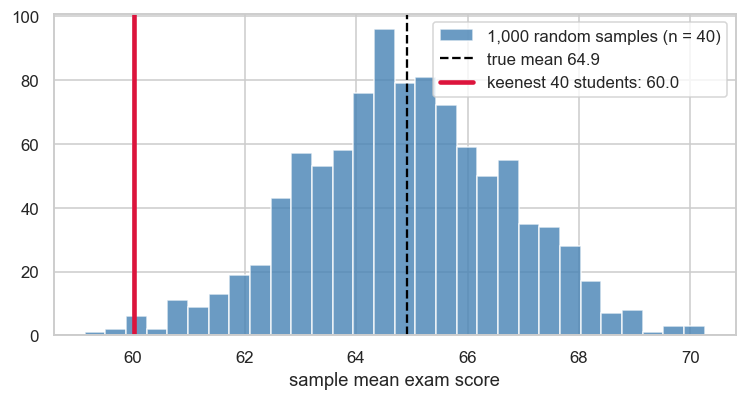

random n=40 : mean of means 64.9, SD 1.82
random n=200: mean of means 64.9, SD 0.71
keenest 40 : 60.0   keenest 200: 59.3   (truth 64.9)


In [9]:
random_means_40 = np.array([rng.choice(population, 40, replace=False).mean() for _ in range(1000)])
valid = df.dropna(subset=["exam_score", "study_hours_week"]).sort_values("study_hours_week", ascending=False)
keen_40 = valid["exam_score"].head(40).mean()
keen_200 = valid["exam_score"].head(200).mean()
random_means_200 = np.array([rng.choice(population, 200, replace=False).mean() for _ in range(1000)])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(random_means_40, bins=30, color="steelblue", alpha=0.8, label="1,000 random samples (n = 40)")
ax.axvline(mu, color="black", ls="--", label=f"true mean {mu:.1f}")
ax.axvline(keen_40, color="crimson", lw=3, label=f"keenest 40 students: {keen_40:.1f}")
ax.set_xlabel("sample mean exam score"); ax.legend(); plt.show()
print(f"random n=40 : mean of means {random_means_40.mean():.1f}, SD {random_means_40.std():.2f}")
print(f"random n=200: mean of means {random_means_200.mean():.1f}, SD {random_means_200.std():.2f}")
print(f"keenest 40 : {keen_40:.1f}   keenest 200: {keen_200:.1f}   (truth {mu:.1f})")

> **Expected:** random means centre on μ ≈ 64.9 (SD ≈ 1.8 at n=40, ≈ 0.7 at n=200). The keenest 40 average ≈ 60.0 and the keenest 200 ≈ 59.3, well below the truth (the top studiers are mostly Engineering, who score lowest: Simpson's paradox again). A bigger biased sample is still off, just more precisely wrong.
> **Questions to ask:**
> 1. "Which sample gave a more *precise* answer at n = 200? Which was more *accurate*?" *(precision vs accuracy)*
> 2. "In real life you don't know μ. How could you tell the sample was biased?" *(compare to known population facts, check who is missing)*
> 3. "Where have we seen non-random missingness before?" *(the missing sleep answers in Class 03)*

---
# 👥 Group 2 · Sampling Distribution & Standard Error

**Question:** How does the typical error of a sample mean shrink as the sample size grows, and does it match the formula σ/√n?

**You must produce**
1. For **n = 10, 30, 100**: draw **2,000 random samples**, compute each sample mean, and the **SD of those means**.
2. Compare each SD with the formula **σ / √n**. Make a small table.
3. One chart that overlays (or places side by side) the three distributions of sample means.
4. **Bonus:** repeat for `commute_minutes` (very skewed). Is the distribution of the *sample means* still skewed at n = 30?
5. One sentence: how much extra data do you need to cut the error in half?

**Look up (function names, not code):** `rng.choice`, `.std()`, `np.sqrt`, `sns.kdeplot` or `plt.hist`, `.skew()`

**📝 Plan / notes (who says what):**

*(double-click to write)*

**✍️ Reporting sentence:**

*(double-click to write)*

**🧾 AI log:** prompt → what I corrected or double-checked →

*(double-click to write)*

,n,SD of sample means,sigma / sqrt(n)
0,10,4.02,3.87
1,30,2.19,2.23
2,100,1.25,1.22


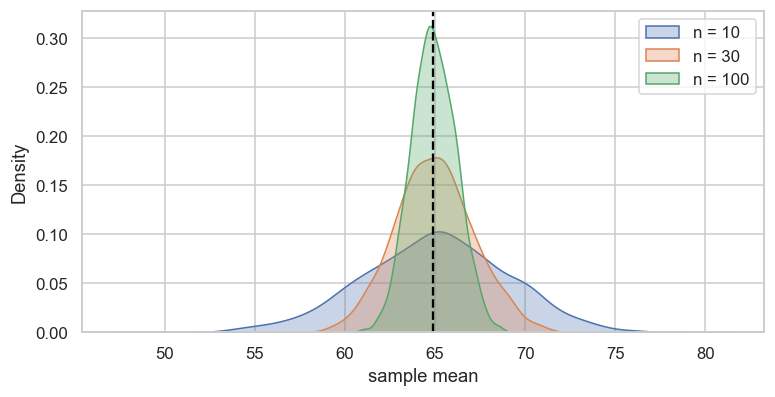

commute raw skew = 1.88   skew of means (n=30) = 0.35


In [16]:
sizes = [10, 30, 100]
means = {n: np.array([rng.choice(population, n).mean() for _ in range(2000)]) for n in sizes}
table = pd.DataFrame({"n": sizes,
                      "SD of sample means": [means[n].std() for n in sizes],
                      "sigma / sqrt(n)": [sigma / np.sqrt(n) for n in sizes]}).round(2)
display(table)

fig, ax = plt.subplots(figsize=(8, 3.8))
for n in sizes:
    sns.kdeplot(means[n], fill=True, alpha=0.3, label=f"n = {n}", ax=ax)
ax.axvline(mu, color="black", ls="--"); ax.set_xlabel("sample mean"); ax.legend(); plt.show()

commute = df["commute_minutes"].dropna()
commute_means = np.array([rng.choice(commute, 30).mean() for _ in range(2000)])
print(f"commute raw skew = {commute.skew():.2f}   skew of means (n=30) = {pd.Series(commute_means).skew():.2f}")

> **Expected:** SDs ≈ 4.0, 2.2, 1.2, matching σ/√n (3.9, 2.2, 1.2). Skew of commute drops from ≈ 1.9 to ≈ 0.35.
> **Questions to ask:**
> 1. "Why do the three curves have the same centre but different widths?"
> 2. "You need to halve the error. How much more data?" *(4×)* "Is it worth going from 100 to 400 students?"
> 3. "What is the difference between the SD of the *data* and the SE?" *(spread of individuals vs precision of the mean)*

---
# 👥 Group 3 · Confidence Intervals

**Question:** What does '95% confident' really mean? Build many intervals and count how often they catch the truth.

**You must produce**
1. Draw **one random sample of 30** and build its 95% confidence interval **by hand** (mean ± t* × SE). Does it contain μ?
2. Repeat **1,000 times**. What share of intervals contain μ?
3. Repeat with **90%** and **99%**. Make a small table of coverage and **average width**.
4. Repeat 95% with **n = 100**. What happens to the width?
5. One chart: the first 30 intervals as horizontal lines, μ as a vertical line, misses in a different colour.

**Look up (function names, not code):** `stats.t.ppf`, `.std(ddof=1)`, `np.sqrt`, `plt.hlines`, `plt.axvline`

**📝 Plan / notes (who says what):**

*(double-click to write)*

**✍️ Reporting sentence:**

*(double-click to write)*

**🧾 AI log:** prompt → what I corrected or double-checked →

*(double-click to write)*

,level,n,coverage,avg width
0,90%,30,91.0%,7.5
1,90%,100,92.5%,4.1
2,95%,30,96.0%,9.0
3,95%,100,96.7%,4.8
4,99%,30,99.1%,12.3
5,99%,100,99.8%,6.4


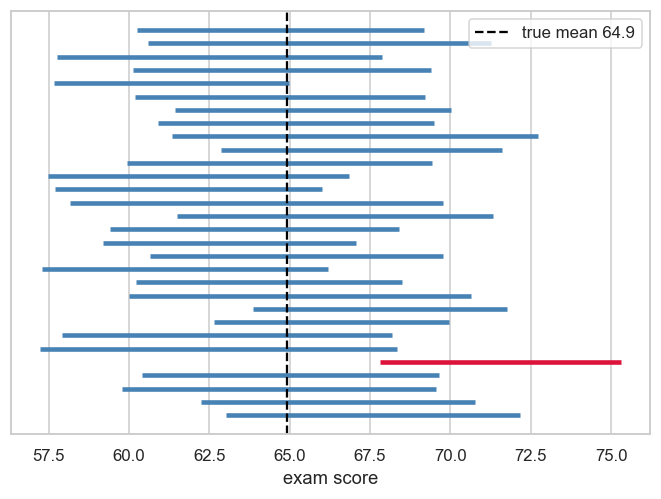

In [23]:
def ci(sample, level=0.95):
    m, se = sample.mean(), sample.std(ddof=1) / np.sqrt(len(sample))
    t = stats.t.ppf((1 + level) / 2, len(sample) - 1)
    return m - t * se, m + t * se

rows = []
for level in (0.90, 0.95, 0.99):
    for n in (30, 100):
        cis = [ci(rng.choice(population, n, replace=False), level) for _ in range(1000)]
        cover = np.mean([lo <= mu <= hi for lo, hi in cis])
        width = np.mean([hi - lo for lo, hi in cis])
        rows.append({"level": f"{level:.0%}", "n": n, "coverage": f"{cover:.1%}", "avg width": round(width, 1)})
display(pd.DataFrame(rows))

demo = [ci(rng.choice(population, 30, replace=False)) for _ in range(30)]
fig, ax = plt.subplots(figsize=(7.5, 5))
for i, (lo, hi) in enumerate(demo):
    ax.hlines(i, lo, hi, color="crimson" if not (lo <= mu <= hi) else "steelblue", lw=3)
ax.axvline(mu, color="black", ls="--", label=f"true mean {mu:.1f}")
ax.set_yticks([]); ax.set_xlabel("exam score"); ax.legend(); plt.show()

> **Expected:** coverage ≈ 91 / 96 / 99 % (close to nominal; small deviations are simulation noise); average width at n = 30 is ≈ 7.5 / 9.0 / 12.3 and at n = 100 ≈ 4.1 / 4.8 / 6.4, about 1.8–1.9× narrower (√(100/30) ≈ 1.8).
> **Questions to ask:**
> 1. "After you computed one interval, what is the probability it contains μ?" *(it either does or doesn't; 95% describes the method)*
> 2. "Why would you ever choose 90% over 99%?" *(precision, narrower interval)*
> 3. "To halve the width of the interval, what must you change?" *(4× n)*

---
# 👥 Group 4 · Hypothesis Test & p-value

**Question:** Do students with a heavy part-time job (more than 15 h/week) score differently from students with no job? Is that gap plausible by luck alone?

**You must produce**
1. State **H₀ and H₁** in words.
2. The two group means, the difference, and **n** in each group.
3. A **Welch t-test** with scipy. Report t and p.
4. A **permutation test** that you write yourself: shuffle the group labels **10,000 times**, record the difference each time, and find how often the shuffled difference is at least as extreme as the real one. Compare with the t-test p.
5. Repeat step 3 for **Hostel vs Home** residents. What is different about the result?
6. One sentence on what p does *and does not* mean here.

**Look up (function names, not code):** `stats.ttest_ind(..., equal_var=False)`, `rng.permutation`, `np.abs`, `np.mean`

**📝 Plan / notes (who says what):**

*(double-click to write)*

**✍️ Reporting sentence:**

*(double-click to write)*

**🧾 AI log:** prompt → what I corrected or double-checked →

*(double-click to write)*

no job 67.2 (n=277) | job>15h 58.4 (n=108) | gap 8.8
Welch t = 5.94, p = 1.61e-08
permutation p = 0.0000  (largest shuffled gap = 5.7, real gap = 8.8)


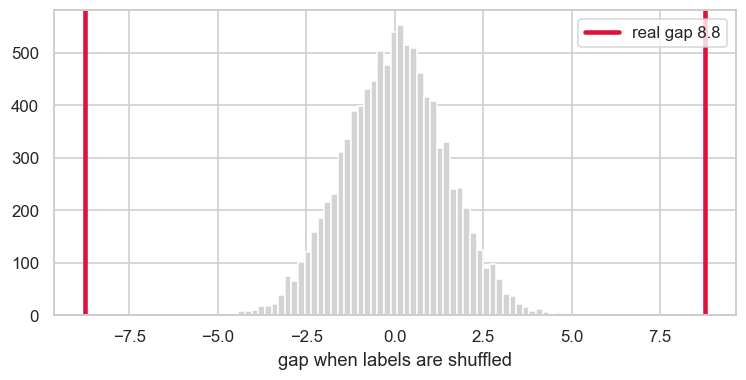

hostel 65.7 vs home 65.4: t = 0.19, p = 0.85


In [30]:
job = df[df.part_time_job_hours_week > 15]["exam_score"].dropna().to_numpy()
nojob = df[df.part_time_job_hours_week == 0]["exam_score"].dropna().to_numpy()
real_diff = nojob.mean() - job.mean()
t = stats.ttest_ind(nojob, job, equal_var=False)
print(f"no job {nojob.mean():.1f} (n={len(nojob)}) | job>15h {job.mean():.1f} (n={len(job)}) | gap {real_diff:.1f}")
print(f"Welch t = {t.statistic:.2f}, p = {t.pvalue:.2e}")

pooled = np.concatenate([nojob, job])
shuffled = np.empty(10_000)
for i in range(10_000):
    perm = rng.permutation(pooled)
    shuffled[i] = perm[:len(nojob)].mean() - perm[len(nojob):].mean()
p_perm = (np.abs(shuffled) >= abs(real_diff)).mean()
print(f"permutation p = {p_perm:.4f}  (largest shuffled gap = {np.abs(shuffled).max():.1f}, real gap = {real_diff:.1f})")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(shuffled, bins=60, color="lightgray"); ax.axvline(real_diff, color="crimson", lw=3, label=f"real gap {real_diff:.1f}")
ax.axvline(-real_diff, color="crimson", lw=3); ax.set_xlabel("gap when labels are shuffled"); ax.legend(); plt.show()

hostel = df[df.residence == "Hostel"]["exam_score"].dropna()
home = df[df.residence == "Home"]["exam_score"].dropna()
t2 = stats.ttest_ind(hostel, home, equal_var=False)
print(f"hostel {hostel.mean():.1f} vs home {home.mean():.1f}: t = {t2.statistic:.2f}, p = {t2.pvalue:.2f}")

> **Expected:** gap ≈ 8.8 points, t ≈ 5.9, p ≈ 1.6e-8; the permutation p prints 0.0000 (the largest of 10,000 shuffled gaps was ≈ 5.7, far below 8.8, so say "p < 1/10,000"). Hostel vs Home: gap ≈ 0.2, p ≈ 0.85.
> **Questions to ask:**
> 1. "The permutation p says 0.0000. Is the probability *really* zero?" *(no: fewer than 1 in 10,000; report p < 0.0001)*
> 2. "Does p tell you that heavy jobs *cause* lower scores?" *(no: association; heavy workers also sleep less)*
> 3. "Hostel vs Home gave p = 0.85. Does that prove residence has no effect?" *(no: absence of evidence; look at the CI)*
> 4. "Is 'p = 0.03' the chance that H₀ is true?" *(no)*

---
# 👥 Group 5 · Effect Size

**Question:** A small p-value says an effect is detectable. Does it say the effect is *big*? Compare several differences by p-value and by Cohen's d.

**You must produce**
1. Make a table with these comparisons on `exam_score`: **job > 15 h vs no job**, **Hostel vs Home**, **Engineering vs Data Science**, **sleep < 6 h vs ≥ 6 h**.
   For each: the difference in means, the **Welch p-value** and **Cohen's d**.
2. Rank the rows by p and then by d. Do the rankings agree?
3. **Simulation:** make two Normal groups with means 63 and 60 and SD 10 (so d = 0.30). Test them with **n = 20, 100 and 1,000 per group**. What happens to p? To d?
4. Write a **rule of thumb** in your own words for how to read p and d together.

**Look up (function names, not code):** `stats.ttest_ind`, `.var(ddof=1)`, pooled SD, `rng.normal`, `pd.DataFrame`

**📝 Plan / notes (who says what):**

*(double-click to write)*

**✍️ Reporting sentence:**

*(double-click to write)*

**🧾 AI log:** prompt → what I corrected or double-checked →

*(double-click to write)*

In [37]:
def cohens_d(a, b):
    a, b = np.asarray(a), np.asarray(b)
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled

score = df.dropna(subset=["exam_score"])
groups = {
    "job > 15 h vs no job (higher = no job)": (score[score.part_time_job_hours_week == 0].exam_score,
                                              score[score.part_time_job_hours_week > 15].exam_score),
    "Hostel vs Home": (score[score.residence == "Hostel"].exam_score, score[score.residence == "Home"].exam_score),
    "Engineering vs Data Science": (score[score.program == "Engineering"].exam_score,
                                    score[score.program == "Data Science"].exam_score),
    "sleep >= 6 h vs < 6 h": (score[score.sleep_hours >= 6].exam_score, score[score.sleep_hours < 6].exam_score),
}
rows = []
for name, (a, b) in groups.items():
    rows.append({"comparison": name, "mean diff": round(a.mean() - b.mean(), 1),
                 "p (Welch)": f"{stats.ttest_ind(a, b, equal_var=False).pvalue:.1e}",
                 "Cohen d": round(cohens_d(a, b), 2)})
display(pd.DataFrame(rows))

sim = []
for n in (20, 100, 1000):
    a, b = rng.normal(63, 10, n), rng.normal(60, 10, n)
    sim.append({"n per group": n, "p": f"{stats.ttest_ind(a, b).pvalue:.3g}", "Cohen d (sample)": round(cohens_d(a, b), 2)})
display(pd.DataFrame(sim))

,comparison,mean diff,p (Welch),Cohen d
0,job > 15 h vs no job (higher = no job),8.8,1.6e-08,0.73
1,Hostel vs Home,0.2,8.5e-01,0.02
2,Engineering vs Data Science,-6.8,4.9e-10,-0.77
3,sleep >= 6 h vs < 6 h,5.3,2.8e-04,0.45


,n per group,p,Cohen d (sample)
0,20,0.0753,0.58
1,100,0.0665,0.26
2,1000,1.76e-09,0.27


> **Expected:** job gap 8.8 points, d ≈ 0.73, p ≈ 2e-8; Hostel vs Home d ≈ 0.02, p ≈ 0.85; Engineering vs Data Science gap −6.8, d ≈ −0.77, p ≈ 5e-10; sleep ≥ 6 h vs < 6 h gap 5.3, d ≈ 0.45, p ≈ 3e-4. The ranking by p and by d can differ (compare sleep with Engineering). Simulation: with a true d of 0.30, p can be non-significant at n = 20 and 100 and tiny (≈ 1e-9) at n = 1,000, while the sample d stays around 0.3 (noisy at small n; exact numbers change with the seed).
> **Questions to ask:**
> 1. "Two results are both 'significant'. How do you decide which matters more?" *(d, and the practical context)*
> 2. "A company reports a significant improvement from 10 million users. What do you ask?" *(how big is it?)*
> 3. "What is a 3-point difference worth in *exam* terms? Is d = 0.3 important?" *(context decides)*
> 4. "Which of today's comparisons would you act on, and why?"

---
## ✅ Checklist (every group)
- [ ] I compared my estimate with the **known population value**
- [ ] I have **one chart** and can explain the axes
- [ ] I wrote **one reporting sentence** (estimate, interval or p, and size)
- [ ] Everyone knows their part. We practised under **5 minutes**